### Проведення серій дослідження впливу розміру графів на прискорення та впливу кількості потоків для паралельного Крускала

In [10]:
# 1. Дані й параметри досліду
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_rows", 500)

RESULTS = "C:/Users/admin/source/repos/Kruskal/results/"
CSV = RESULTS + "kpar_threads.csv"
MIN_EDGES = 1_000_000      # серія 2: лише великі графи
P_SERIES1 = 12              # серія 1: кількість потоків для порівняння за обсягом даних

PARAMS = ["threads", "threshold", "partition_block", "filter_block", "par_cutoff", "psort_cutoff", "qsort_cutoff"]

def experiment_params(df):
    rows = {}
    for alg, d in df.groupby("algorithm", sort=False):
        row = {}
        for c in PARAMS:
            vals = sorted(d[c].dropna().unique())
            row[c] = ", ".join(str(int(v)) for v in vals) if vals else "-"
        repeats = d.groupby(["graph"] + PARAMS, dropna=False)["repeat"].nunique()
        row["повторів"] = f"{repeats.min()}–{repeats.max()}" if repeats.min() != repeats.max() else str(repeats.min())
        rows[alg] = row
    graphs = df["graph"].unique()
    print(f"Графи ({len(graphs)}): {', '.join(graphs)}")
    return pd.DataFrame(rows).T

df = pd.read_csv(CSV)
order = list(df["graph"].unique())                                       # порядок графів як у плані
info = df.groupby("graph", sort=False)[["family", "V", "E"]].first()     # сімейство і розмір кожного графа
big = [g for g in order if info.loc[g, "E"] >= MIN_EDGES]                # великі графи для серії 2

display(experiment_params(df))

Графи (19): B1, B2, B3, B4, B5, B6, B7, B8, B9, B10, B11, G1, C1, C2, C3, C4, C5, C6, C7


,threads,threshold,partition_block,filter_block,par_cutoff,psort_cutoff,qsort_cutoff,повторів
kruskal,1,-,-,-,-,-,-,6–25
kruskal-par,"1, 2, 4, 6, 8, 12, 16",-,-,-,-,-,-,6–25


In [11]:
# 2. Середній час, прискорення й ефективність
cols = ["total_ms", "sort_ms", "dsu_ms"]

# Послідовний Крускал (еталон): середнє по повторах на кожному графі
seq = df[df["algorithm"] == "kruskal"].groupby("graph")[cols].mean().reindex(order)

# Паралельний Крускал: середнє по повторах для кожної пари (граф, кількість потоків)
par = df[df["algorithm"] == "kruskal-par"].groupby(["graph", "threads"], as_index=False)[cols].mean()
par["speedup"] = par["graph"].map(seq["total_ms"]) / par["total_ms"]   # S_p = T_seq / T_par(p)
par["efficiency"] = par["speedup"] / par["threads"]                     # E_p = S_p / p
threads = sorted(par["threads"].unique())

# Як розподіляється час послідовного Крускала
seq_table = seq.copy()
seq_table["інше_ms"] = seq["total_ms"] - seq["sort_ms"] - seq["dsu_ms"]   # копіювання графа і звільнення пам'яті
seq_table["частка DSU, %"] = 100 * seq["dsu_ms"] / seq["total_ms"]
seq_table.insert(0, "E", info["E"])
seq_table.insert(0, "V", info["V"])
print("Послідовний Крускал, середній час, мс:")
display(seq_table.round(2))

Послідовний Крускал, середній час, мс:


,V,E,total_ms,sort_ms,dsu_ms,інше_ms,"частка DSU, %"
graph,,,,,,,
B1,8000,16000,1.02,0.84,0.18,0.01,17.58
B2,8000,32000,2.05,1.78,0.23,0.04,11.27
B3,8000,64000,4.18,3.83,0.28,0.08,6.60
B4,8000,128000,8.59,8.02,0.28,0.30,3.27
B5,8000,256000,17.48,16.60,0.28,0.60,1.62
B6,8000,512000,35.50,34.04,0.31,1.15,0.87
B7,8000,1024000,72.02,69.43,0.33,2.26,0.46
B8,8000,2048000,140.71,135.65,0.29,4.77,0.21
B9,8000,4096000,275.10,264.86,0.30,9.95,0.11


In [20]:
seq_table.to_excel(RESULTS + "kruskal_seq_time_parts.xlsx")

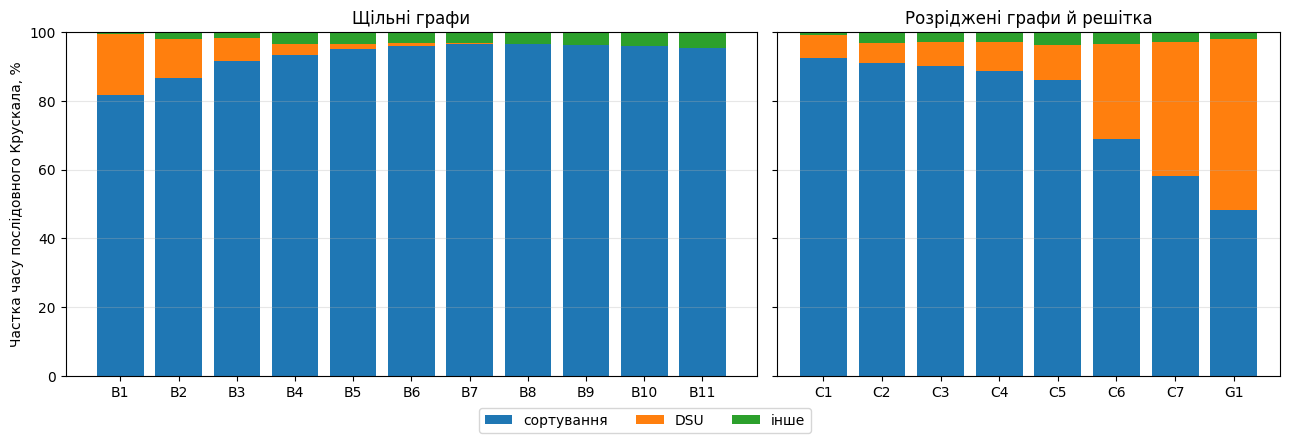

In [19]:
# 9. З чого складається час послідовного Крускала (частки для кожного графа)
shares = pd.DataFrame({
    "сортування": 100 * seq["sort_ms"] / seq["total_ms"],
    "DSU": 100 * seq["dsu_ms"] / seq["total_ms"],
    "інше": 100 * (seq["total_ms"] - seq["sort_ms"] - seq["dsu_ms"]) / seq["total_ms"],
}).reindex(order)

groups = [("Щільні графи", [g for g in order if info.loc[g, "family"] == "dense"]),
          ("Розріджені графи й решітка", [g for g in order if info.loc[g, "family"] == "sparse"]
                                          + [g for g in order if info.loc[g, "family"] == "grid"])]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True,
                         gridspec_kw={"width_ratios": [len(g) for _, g in groups]})
for ax, (title, graphs) in zip(axes, groups):
    d = shares.loc[graphs]
    pos = np.arange(len(graphs))
    bottom = np.zeros(len(graphs))
    for part in ["сортування", "DSU", "інше"]:
        ax.bar(pos, d[part], bottom=bottom, label=part)
        bottom += d[part].to_numpy()
    ax.set_xticks(pos, graphs)
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Частка часу послідовного Крускала, %")
axes[0].set_ylim(0, 100)
fig.tight_layout()
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, fontsize=10, bbox_to_anchor=(0.5, -0.06))
fig.savefig(RESULTS + "kruskal_seq_time_parts.png", dpi=200, bbox_inches="tight")
plt.show()

In [12]:
# 3. Серія 2. Вплив кількості потоків (великі графи)
print("Прискорення S_p відносно послідовного Крускала:")
display(par.pivot(index="graph", columns="threads", values="speedup").reindex(big).round(2))

print("Ефективність E_p = S_p / p:")
display(par.pivot(index="graph", columns="threads", values="efficiency").reindex(big).round(2))

# Найбільше прискорення на кожному графі і теоретична межа за законом Амдала:
# якщо паралельне лише сортування, а DSU і решта послідовні, то S <= total / (dsu + інше)
best = (par[par["graph"].isin(big)]
          .loc[lambda d: d.groupby("graph")["speedup"].idxmax()]
          .set_index("graph").reindex(big))
# Закон Амдала: f - частка послідовної роботи (DSU, копіювання) в часі послідовного Крускала
f = (seq["total_ms"] - seq["sort_ms"]) / seq["total_ms"]
p_best = best["threads"]
best_table = pd.DataFrame({
    "частка f": f.reindex(big),
    "найкраще p": p_best,
    "найбільше S": best["speedup"],
    "межа при цьому p": 1 / (f.reindex(big) + (1 - f.reindex(big)) / p_best),
    "межа при p → ∞": 1 / f.reindex(big),
})
print("Найбільше прискорення і межа за законом Амдала:")
display(best_table.round(2))

Прискорення S_p відносно послідовного Крускала:


threads,1,2,4,6,8,12,16
graph,,,,,,,
B7,1.00,1.77,2.95,3.69,3.99,4.54,3.88
B8,1.00,1.70,2.72,3.04,3.59,3.77,3.49
B9,1.01,1.71,2.66,3.04,3.41,3.61,3.33
B10,1.00,1.71,2.70,2.98,3.32,3.46,3.26
B11,1.00,1.71,2.73,3.07,3.33,3.47,3.34
G1,1.03,1.28,1.49,1.45,1.57,1.58,1.59
C4,1.00,1.58,2.34,2.72,2.89,3.03,2.84
C5,1.01,1.62,2.35,2.55,2.76,2.75,2.68
C6,1.01,1.43,1.83,1.93,2.04,2.05,1.98


Ефективність E_p = S_p / p:


threads,1,2,4,6,8,12,16
graph,,,,,,,
B7,1.00,0.89,0.74,0.62,0.50,0.38,0.24
B8,1.00,0.85,0.68,0.51,0.45,0.31,0.22
B9,1.01,0.85,0.66,0.51,0.43,0.30,0.21
B10,1.00,0.85,0.68,0.50,0.42,0.29,0.20
B11,1.00,0.86,0.68,0.51,0.42,0.29,0.21
G1,1.03,0.64,0.37,0.24,0.20,0.13,0.10
C4,1.00,0.79,0.58,0.45,0.36,0.25,0.18
C5,1.01,0.81,0.59,0.42,0.34,0.23,0.17
C6,1.01,0.72,0.46,0.32,0.25,0.17,0.12


Найбільше прискорення і межа за законом Амдала:


,частка f,найкраще p,найбільше S,межа при цьому p,межа при p → ∞
graph,,,,,
B7,0.04,12,4.54,8.60,27.83
B8,0.04,12,3.77,8.60,27.78
B9,0.04,12,3.61,8.51,26.85
B10,0.04,12,3.46,8.23,24.00
B11,0.05,12,3.47,7.93,21.45
G1,0.52,16,1.59,1.83,1.93
C4,0.11,12,3.03,5.38,8.95
C5,0.14,8,2.76,4.03,7.11
C6,0.31,12,2.05,2.72,3.23


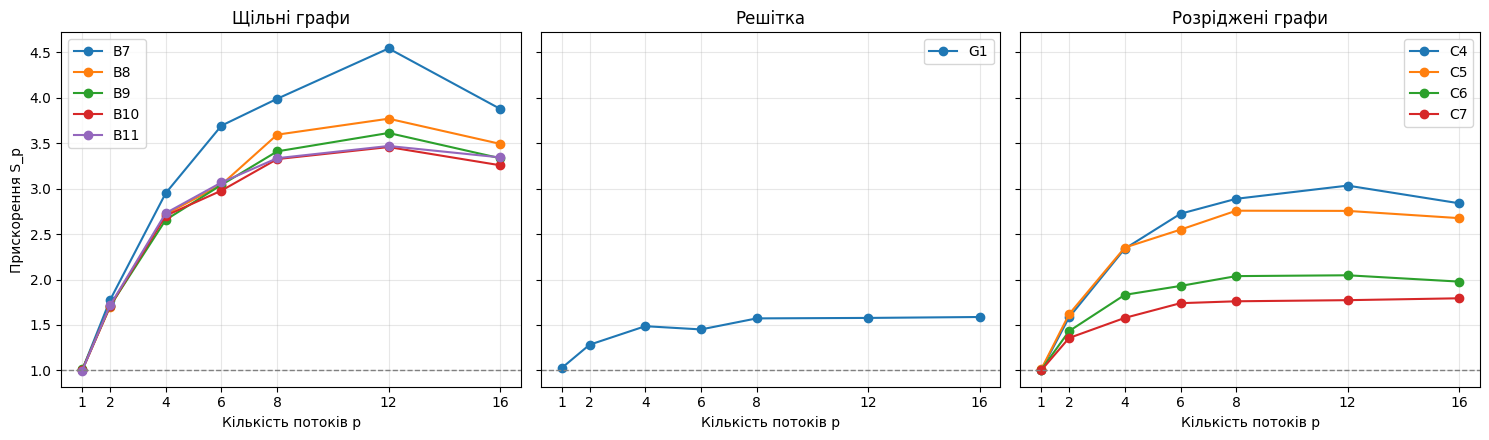

In [13]:
# 4. Серія 2. Графік прискорення від кількості потоків
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
families = [("dense", "Щільні графи"), ("grid", "Решітка"), ("sparse", "Розріджені графи")]
for ax, (family, title) in zip(axes, families):
    for g in [g for g in big if info.loc[g, "family"] == family]:
        d = par[par["graph"] == g].sort_values("threads")
        ax.plot(d["threads"], d["speedup"], marker="o", label=g)
    ax.axhline(1, color="gray", lw=1, ls="--")
    ax.set_xticks(threads)
    ax.set_xlabel("Кількість потоків p")
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=10)
axes[0].set_ylabel("Прискорення S_p")
fig.tight_layout()
fig.savefig(RESULTS + "kpar_speedup_threads.png", dpi=200, bbox_inches="tight")
plt.show()

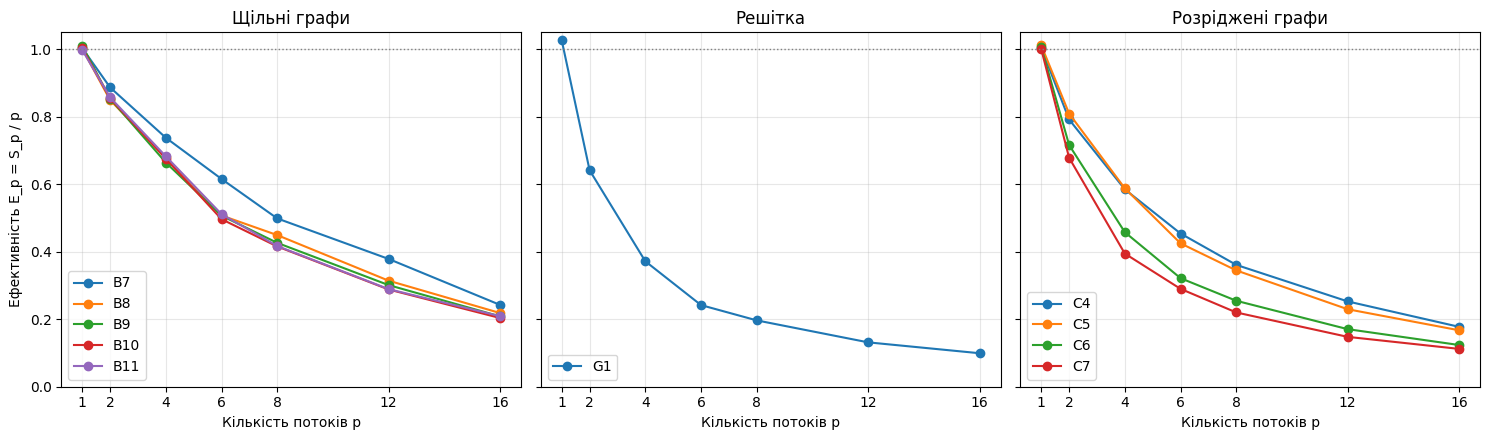

In [14]:
# 5. Серія 2. Графік ефективності від кількості потоків
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
families = [("dense", "Щільні графи"), ("grid", "Решітка"), ("sparse", "Розріджені графи")]
for ax, (family, title) in zip(axes, families):
    for g in [g for g in big if info.loc[g, "family"] == family]:
        d = par[par["graph"] == g].sort_values("threads")
        ax.plot(d["threads"], d["efficiency"], marker="o", label=g)
    ax.axhline(1, color="gray", lw=1, ls=":")      # ідеальна ефективність
    ax.set_xticks(threads)
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("Кількість потоків p")
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=10)
axes[0].set_ylabel("Ефективність E_p = S_p / p")
fig.tight_layout()
fig.savefig(RESULTS + "kpar_efficiency_threads.png", dpi=200, bbox_inches="tight")
plt.show()

In [15]:
# 6. Серія 1. Вплив обсягу даних (усі графи, p = P_SERIES1)
at_p = par[par["threads"] == P_SERIES1].set_index("graph").reindex(order)
f_all = (seq["total_ms"] - seq["sort_ms"]) / seq["total_ms"]        # частка послідовної роботи на кожному графі

series1 = pd.DataFrame({
    "V": info["V"],
    "E": info["E"],
    "Крускал, мс": seq["total_ms"],
    f"паралельний (p={P_SERIES1}), мс": at_p["total_ms"],
    "Прискорення": at_p["speedup"],
    "межа Амдала": 1 / (f_all + (1 - f_all) / P_SERIES1),
}).reindex(order)
print(f"Серія 1: прискорення при p = {P_SERIES1}")
display(series1.round(2))

Серія 1: прискорення при p = 12


,V,E,"Крускал, мс","паралельний (p=12), мс",Прискорення,межа Амдала
graph,,,,,,
B1,8000,16000,1.02,1.31,0.78,4.00
B2,8000,32000,2.05,1.44,1.42,4.88
B3,8000,64000,4.18,1.67,2.50,6.23
B4,8000,128000,8.59,2.93,2.94,6.90
B5,8000,256000,17.48,4.43,3.95,7.72
B6,8000,512000,35.50,7.86,4.52,8.26
B7,8000,1024000,72.02,15.86,4.54,8.60
B8,8000,2048000,140.71,37.33,3.77,8.60
B9,8000,4096000,275.10,76.16,3.61,8.51


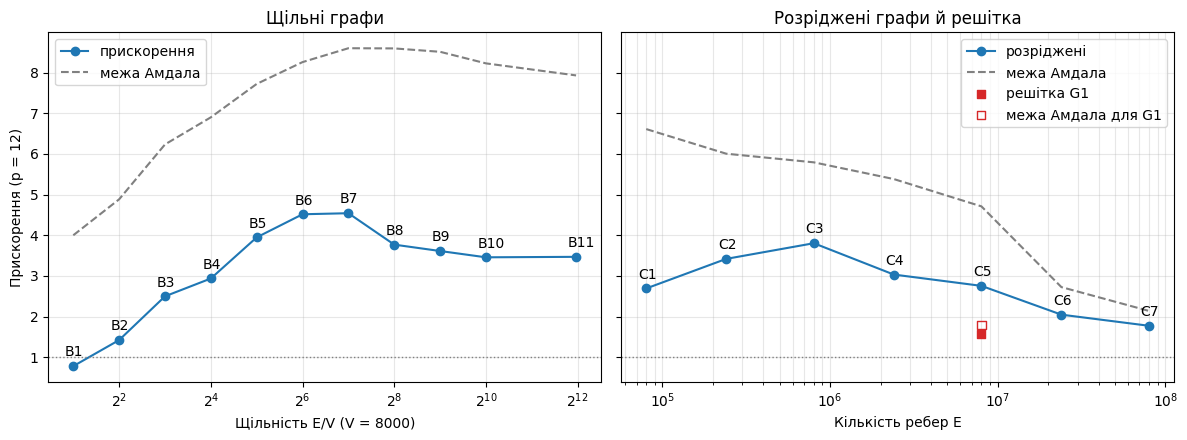

In [16]:
# 7. Серія 1. Графік прискорення від обсягу даних
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

# Щільні графи: однакова кількість вершин, змінюється щільність E/V
dense = [g for g in order if info.loc[g, "family"] == "dense"]
x = info.loc[dense, "E"] / info.loc[dense, "V"]
axes[0].plot(x, series1.loc[dense, "Прискорення"], marker="o", label="прискорення")
axes[0].plot(x, series1.loc[dense, "межа Амдала"], ls="--", color="gray", label="межа Амдала")
for xi, yi, g in zip(x, series1.loc[dense, "Прискорення"], dense):
    axes[0].annotate(g, (xi, yi), textcoords="offset points", xytext=(-6, 7), fontsize=10)
axes[0].set_xscale("log", base=2)
axes[0].set_xlabel("Щільність E/V (V = 8000)")
axes[0].set_title("Щільні графи")

# Розріджені графи: E/V = 8, змінюється розмір; решітка — окрема точка
sparse = [g for g in order if info.loc[g, "family"] == "sparse"]
grid = [g for g in order if info.loc[g, "family"] == "grid"]
axes[1].plot(info.loc[sparse, "E"], series1.loc[sparse, "Прискорення"], marker="o", label="розріджені")
axes[1].plot(info.loc[sparse, "E"], series1.loc[sparse, "межа Амдала"], ls="--", color="gray", label="межа Амдала")
for xi, yi, g in zip(info.loc[sparse, "E"], series1.loc[sparse, "Прискорення"], sparse):
    axes[1].annotate(g, (xi, yi), textcoords="offset points", xytext=(-6, 7), fontsize=10)
axes[1].scatter(info.loc[grid, "E"], series1.loc[grid, "Прискорення"], marker="s", color="tab:red",
                zorder=3, label="решітка G1")
axes[1].scatter(info.loc[grid, "E"], series1.loc[grid, "межа Амдала"], marker="s", facecolors="none",
                edgecolors="tab:red", zorder=3, label="межа Амдала для G1")
axes[1].set_xscale("log")
axes[1].set_xlabel("Кількість ребер E")
axes[1].set_title("Розріджені графи й решітка")

for ax in axes:
    ax.axhline(1, color="gray", lw=1, ls=":")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=10)
axes[0].set_ylabel(f"Прискорення (p = {P_SERIES1})")
fig.tight_layout()
fig.savefig(RESULTS + "kpar_speedup_size.png", dpi=200, bbox_inches="tight")
plt.show()

Частка сортування в загальному часі паралельного Крускала, %:


threads,1,2,4,6,8,12,16
graph,,,,,,,
B11,95.34,89.37,83.02,80.56,78.58,77.57,78.28
C4,88.84,78.54,67.48,62.50,60.57,56.25,61.12
C7,58.12,43.42,30.19,28.47,25.73,25.27,25.28
G1,49.67,34.07,23.19,19.69,18.90,19.28,19.86


Частка DSU в загальному часі паралельного Крускала, %:


threads,1,2,4,6,8,12,16
graph,,,,,,,
B11,0.01,0.02,0.04,0.04,0.04,0.05,0.05
C4,8.23,14.42,21.99,25.25,26.41,29.71,26.18
C7,38.94,51.39,63.57,64.81,67.52,68.00,67.99
G1,48.14,62.33,72.58,76.19,76.68,76.28,75.61


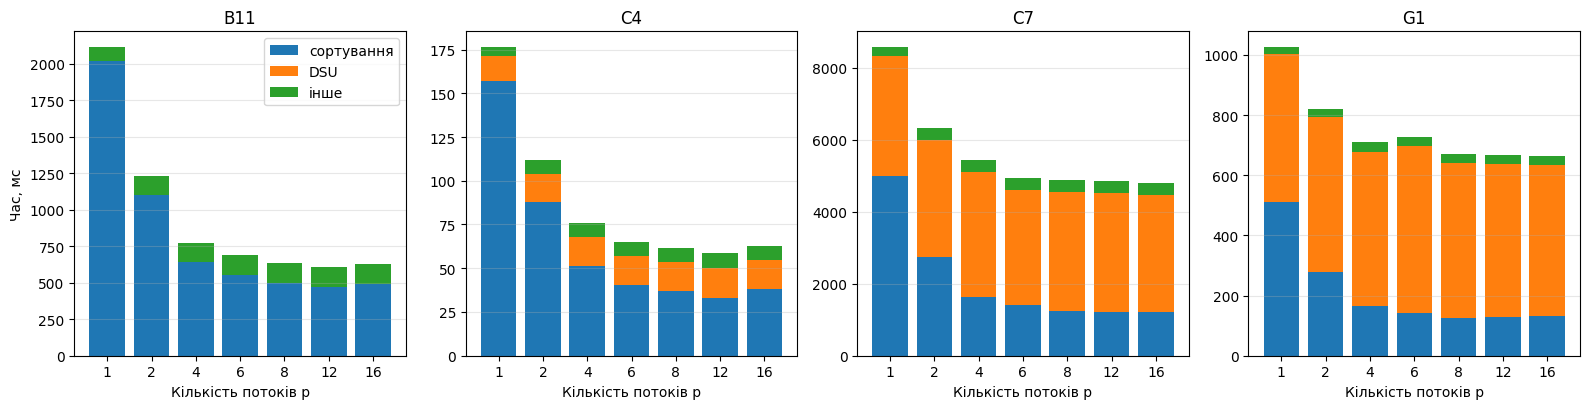

In [18]:
#8. З чого складається час паралельного Крускала
GRAPHS = ["B11", "C4", "C7", "G1"]    # представники сімейств: щільний, два розріджені, решітка

parts = par[par["graph"].isin(GRAPHS)].copy()
parts["інше_ms"] = parts["total_ms"] - parts["sort_ms"] - parts["dsu_ms"]   # копіювання графа, звільнення пам'яті
parts["частка сортування, %"] = 100 * parts["sort_ms"] / parts["total_ms"]
parts["частка DSU, %"] = 100 * parts["dsu_ms"] / parts["total_ms"]

print("Частка сортування в загальному часі паралельного Крускала, %:")
display(parts.pivot(index="graph", columns="threads", values="частка сортування, %").reindex(GRAPHS).round(2))
print("Частка DSU в загальному часі паралельного Крускала, %:")
display(parts.pivot(index="graph", columns="threads", values="частка DSU, %").reindex(GRAPHS).round(2))

# Стовпчики: час кожної частини (мс) для кожної кількості потоків
fig, axes = plt.subplots(1, len(GRAPHS), figsize=(4 * len(GRAPHS), 4.2))
for ax, g in zip(axes, GRAPHS):
    d = parts[parts["graph"] == g].sort_values("threads")
    pos = np.arange(len(d))
    ax.bar(pos, d["sort_ms"], label="сортування")
    ax.bar(pos, d["dsu_ms"], bottom=d["sort_ms"], label="DSU")
    ax.bar(pos, d["інше_ms"], bottom=d["sort_ms"] + d["dsu_ms"], label="інше")
    ax.set_xticks(pos, [str(p) for p in d["threads"]])
    ax.set_xlabel("Кількість потоків p")
    ax.set_title(g)
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Час, мс")
axes[0].legend(fontsize=10)
fig.tight_layout()
fig.savefig(RESULTS + "kpar_time_parts.png", dpi=200, bbox_inches="tight")
plt.show()